# CineMatch — Movie Recommender System
### Exploratory Data Analysis & Model Walkthrough

This notebook walks through:
1. Dataset exploration and visualization
2. Collaborative Filtering (User-Based & Item-Based)
3. Matrix Factorization via SVD
4. Content-Based Filtering using TF-IDF
5. Hybrid Ensemble and Evaluation against baselines

Run `python generate_data.py` from the project root first. The synthetic ratings have planted structure (biases, hidden tastes, genres and self-selection), so every model is compared with simple baselines it should beat.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, '..')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from scipy.sparse import csr_matrix

sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.dpi'] = 100
Path('../docs').mkdir(exist_ok=True)

from src.data_loader import DataLoader
from src.baselines import BiasBaseline, PopularityRecommender
from src.collaborative_filter import CollaborativeFilter
from src.matrix_factorization import MatrixFactorization
from src.content_based import ContentBasedFilter
from src.hybrid_recommender import HybridRecommender
from src.evaluator import Evaluator

print('Imports OK')

Imports OK


## 1. Load & Inspect Data

In [2]:
loader = DataLoader(data_dir='../data')
loader.load().preprocess()

print('=== Dataset Summary ===')
for k, v in loader.summary().items():
    print(f'  {k}: {v}')

2026-10-26 18:19:56,759 [INFO] Loading datasets...


2026-10-26 18:19:56,851 [INFO] Data validation passed.


2026-10-26 18:19:56,853 [INFO] Loaded 100,000 ratings | 1,682 movies | 943 users


2026-10-26 18:19:56,853 [INFO] Preprocessing: filtering sparse users and movies...


2026-10-26 18:19:56,869 [INFO] After filtering: 99,529 ratings | 939 users | 1484 movies


=== Dataset Summary ===
  n_ratings: 99529
  n_users: 939
  n_movies: 1484
  avg_rating: 3.532
  rating_std: 1.125
  sparsity: 0.9285750167207759


In [3]:
loader.ratings.head(10)

,userId,movieId,rating,timestamp
0,1,4,2.0,885857357
1,1,14,1.0,876527295
2,1,57,4.0,889333689
3,1,77,3.0,887487067
4,1,103,4.0,876428705
5,1,116,4.0,892492388
6,1,157,4.0,890854232
7,1,192,3.0,880133996
8,1,199,4.0,888663714
9,1,205,1.0,884315917


In [4]:
loader.movies.head(10)

,movieId,title,year,genres
0,1,Toy Story,1991,Comedy|Mystery
1,2,GoldenEye,1999,Adventure
2,3,Four Rooms,1991,Comedy|Drama|Romance
3,4,Get Shorty,1998,Crime|Romance
4,5,Copycat,1994,Thriller
5,6,Twelve Monkeys,1993,Comedy|Fantasy|Mystery
6,7,Babe,1990,Children|Drama
7,8,Dead Man Walking,1996,Romance|Thriller
8,9,Seven,1997,Musical
9,10,Usual Suspects,1994,Thriller


## 2. Exploratory Data Analysis

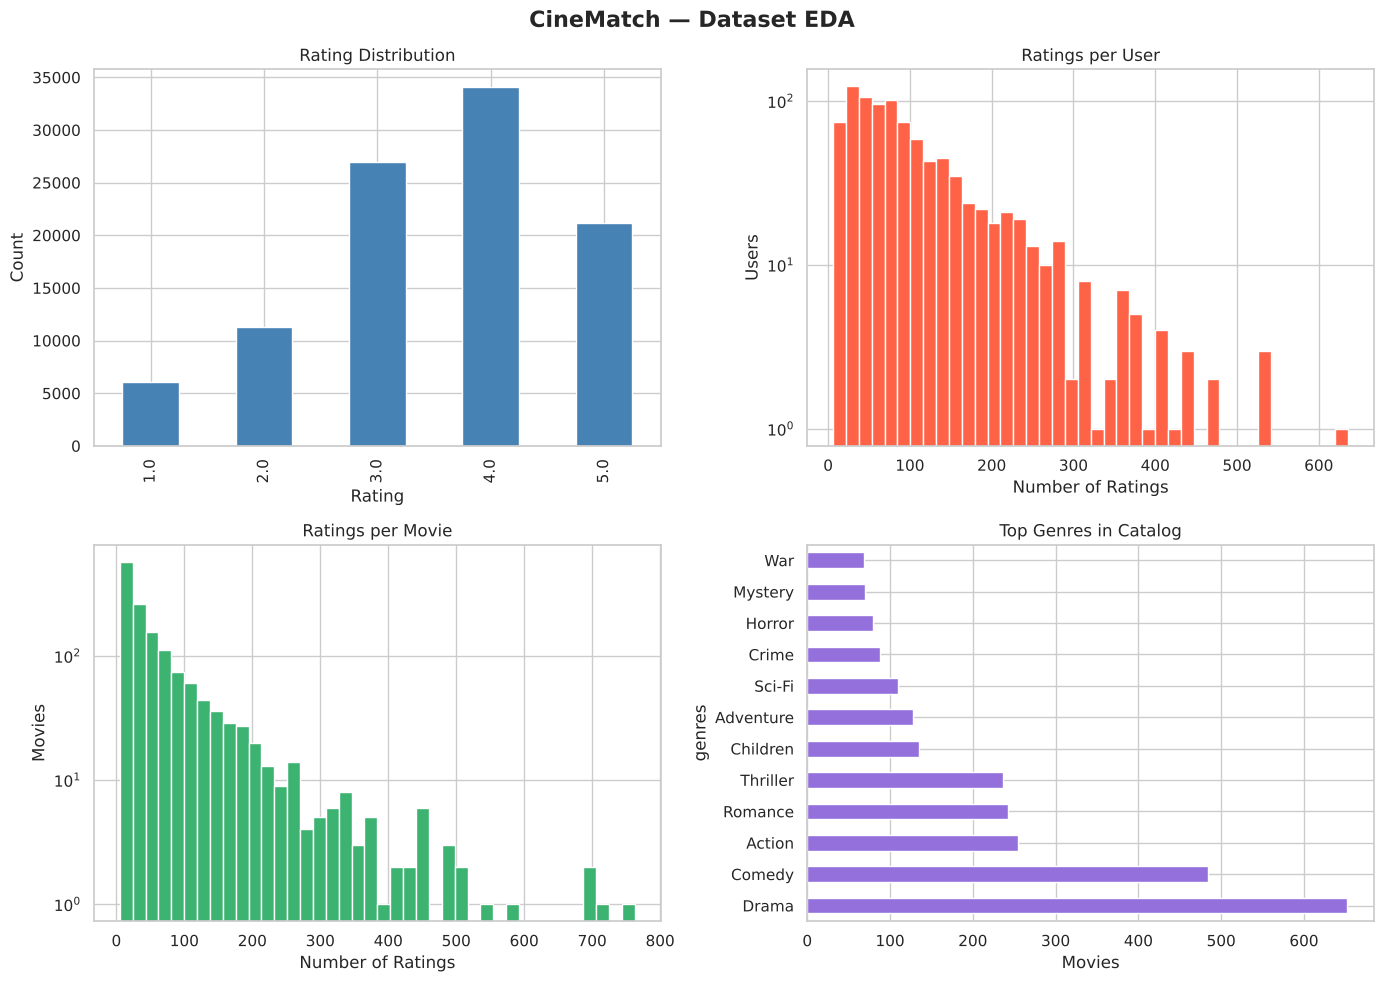

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle('CineMatch — Dataset EDA', fontsize=16, fontweight='bold')

# Rating distribution
ax = axes[0, 0]
loader.ratings['rating'].value_counts().sort_index().plot(kind='bar', ax=ax, color='steelblue', edgecolor='white')
ax.set_title('Rating Distribution')
ax.set_xlabel('Rating')
ax.set_ylabel('Count')

# Ratings per user (log scale)
ax = axes[0, 1]
user_counts = loader.ratings['userId'].value_counts()
ax.hist(user_counts, bins=40, color='tomato', edgecolor='white')
ax.set_title('Ratings per User')
ax.set_xlabel('Number of Ratings')
ax.set_ylabel('Users')
ax.set_yscale('log')

# Ratings per movie
ax = axes[1, 0]
movie_counts = loader.ratings['movieId'].value_counts()
ax.hist(movie_counts, bins=40, color='mediumseagreen', edgecolor='white')
ax.set_title('Ratings per Movie')
ax.set_xlabel('Number of Ratings')
ax.set_ylabel('Movies')
ax.set_yscale('log')

# Genre frequency
ax = axes[1, 1]
genre_series = loader.movies['genres'].str.split('|').explode()
genre_counts = genre_series.value_counts().head(12)
genre_counts.plot(kind='barh', ax=ax, color='mediumpurple', edgecolor='white')
ax.set_title('Top Genres in Catalog')
ax.set_xlabel('Movies')

plt.tight_layout()
plt.savefig('../docs/eda_plots.png', dpi=150, bbox_inches='tight')
plt.show()

## 3. User-Item Matrix & Sparsity

2026-10-26 18:19:59,137 [INFO] Built user-item matrix: 939 x 1484 | Density: 7.1425%


Matrix shape: (939, 1484)
Non-zero entries: 99,529
Density: 7.1425%


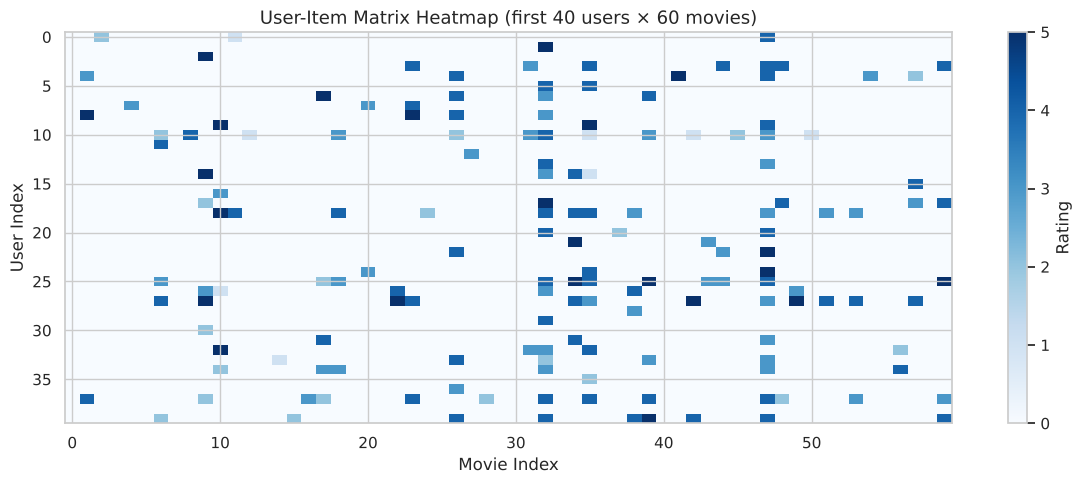

In [6]:
uim = loader.build_user_item_matrix()
print(f'Matrix shape: {uim.shape}')
print(f'Non-zero entries: {uim.nnz:,}')
print(f'Density: {uim.nnz / (uim.shape[0] * uim.shape[1]):.4%}')

# Visualize a small submatrix
sub = uim[:40, :60].toarray()
fig, ax = plt.subplots(figsize=(12, 5))
im = ax.imshow(sub, aspect='auto', cmap='Blues', interpolation='nearest')
ax.set_title('User-Item Matrix Heatmap (first 40 users × 60 movies)', fontsize=13)
ax.set_xlabel('Movie Index')
ax.set_ylabel('User Index')
plt.colorbar(im, ax=ax, label='Rating')
plt.tight_layout()
plt.savefig('../docs/matrix_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()

## 4. Matrix Factorization (SVD)

In [7]:
train, test = loader.train_test_split(test_size=0.2)

# Build train-only matrix
row = train['userId'].map(loader.user_id_map)
col = train['movieId'].map(loader.item_id_map)
train_matrix = csr_matrix((train['rating'].values, (row, col)), shape=uim.shape)

mf = MatrixFactorization()  # 10 factors, chosen by train.py on a validation split
mf.fit(train_matrix)
print('MF model trained.')

2026-10-26 18:20:00,016 [INFO] Train: 79,623 | Test: 19,906


2026-10-26 18:20:00,029 [INFO] Fitting SVD with 10 factors...


2026-10-26 18:20:00,376 [INFO] SVD complete. User factors: (939, 10), Item factors: (1484, 10)


MF model trained.


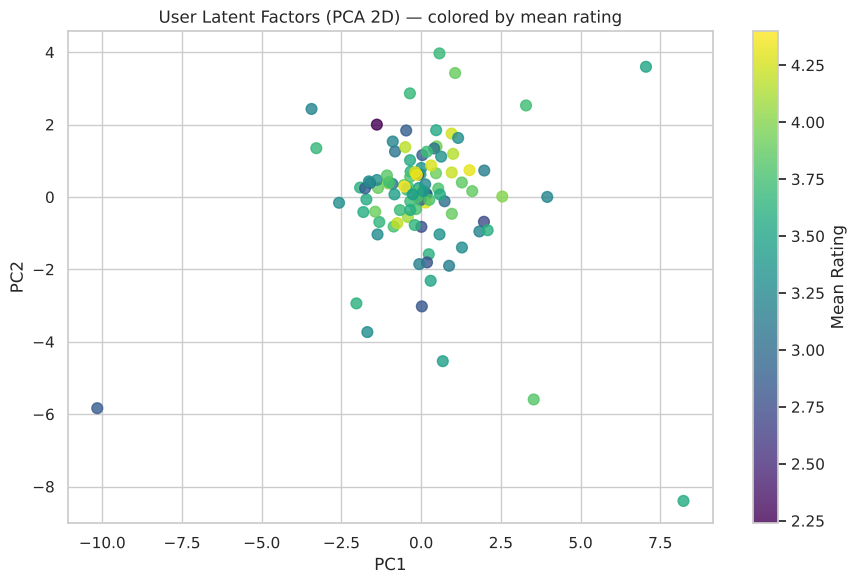

In [8]:
# Visualize latent factors for first 100 users using PCA
from sklearn.decomposition import PCA

pca = PCA(n_components=2, random_state=42)
user_2d = pca.fit_transform(mf.user_factors[:100])

fig, ax = plt.subplots(figsize=(9, 6))
scatter = ax.scatter(user_2d[:, 0], user_2d[:, 1], 
                     c=mf.user_means[:100], cmap='viridis', alpha=0.8, s=60)
plt.colorbar(scatter, ax=ax, label='Mean Rating')
ax.set_title('User Latent Factors (PCA 2D) — colored by mean rating', fontsize=12)
ax.set_xlabel('PC1')
ax.set_ylabel('PC2')
plt.tight_layout()
plt.savefig('../docs/latent_factors.png', dpi=150, bbox_inches='tight')
plt.show()

## 5. Sample Recommendations

In [9]:
# Pick a user with decent activity
active_users = train['userId'].value_counts()
sample_uid = active_users.index[5]

uidx = loader.user_id_map[sample_uid]
mf_recs = mf.recommend(uidx, train_matrix, n=10)

print(f'Top 10 MF recommendations for User {sample_uid}:')
print(f'(User has rated {active_users[sample_uid]} movies)\n')

for rank, (iidx, score) in enumerate(mf_recs, 1):
    mid = loader.reverse_item_map[iidx]
    title = loader.get_movie_title(mid)
    print(f'  {rank:2}. {title:<40} (score: {score:.2f})')

Top 10 MF recommendations for User 58:
(User has rated 378 movies)

   1. Film 711                                 (score: 5.00)
   2. Film 689                                 (score: 4.96)
   3. Film 1467                                (score: 4.67)
   4. Film 1382                                (score: 4.36)
   5. Film 549                                 (score: 4.30)
   6. Film 1348                                (score: 4.22)
   7. Film 793                                 (score: 4.18)
   8. Film 343                                 (score: 4.17)
   9. Film 1589                                (score: 4.17)
  10. Film 1651                                (score: 4.17)


## 6. Hybrid Recommender

In [10]:
# Weights (CF 0.6, MF 0.4, CB 0.0) and 10 SVD factors were chosen by train.py
# on a validation split held out of the training data
hybrid = HybridRecommender()
hybrid.fit(train_matrix, loader.movies, train, loader.user_id_map, loader.item_id_map)
print('Hybrid model trained.')

2026-10-26 18:20:00,966 [INFO] === Training Hybrid Recommender ===


2026-10-26 18:20:00,968 [INFO] [1/3] Fitting Collaborative Filter...


2026-10-26 18:20:00,978 [INFO] Computing item-item cosine similarity...


2026-10-26 18:20:01,044 [INFO] Similarity matrix shape: (1484, 1484)


2026-10-26 18:20:01,048 [INFO] [2/3] Fitting Matrix Factorization...


...

2026-10-26 18:20:01,257 [INFO] [3/3] Fitting Content-Based Filter...


2026-10-26 18:20:01,257 [INFO] Building content profiles with TF-IDF on genres...


2026-10-26 18:20:01,274 [INFO] Item profiles: (1682, 18) | Vocab: 18 genres


2026-10-26 18:20:01,275 [INFO] === Training complete ===


Hybrid model trained.


In [11]:
recs_df = hybrid.recommend(sample_uid, n=10)
print(f'Hybrid recommendations for User {sample_uid}:')
recs_df

Hybrid recommendations for User 58:


,rank,movieId,title,genres,predicted_score
0,1,689,Film 689,Comedy|Drama,0.9958
1,2,1467,Film 1467,Romance,0.8547
2,3,711,Film 711,Children|Drama|Fantasy,0.8240
3,4,1258,Film 1258,Comedy|Drama,0.7982
4,5,44,Free Willy 2,Thriller,0.7863
5,6,1651,Film 1651,Fantasy,0.7790
6,7,549,Film 549,Drama|Fantasy,0.7659
7,8,538,Film 538,Drama,0.7545
8,9,1238,Film 1238,Documentary,0.7494
9,10,1348,Film 1348,Romance,0.7403


## 7. Evaluation

Every model is compared with a baseline it has to beat: the global mean and a bias model (global mean + user bias + movie bias) for rating prediction, and recommending the most-rated movies for ranking.

In [12]:
ev = Evaluator(train, test, relevance_threshold=4.0)

global_mean = train['rating'].mean()
bias = BiasBaseline().fit(train_matrix)
item_knn = CollaborativeFilter(mode='item', k=20).fit(train_matrix)

rating_models = {
    'Global mean': lambda u, i: global_mean,
    'Bias baseline': bias.predict,
    'Matrix factorization': mf.predict,
    'Item-KNN': item_knn.predict_user_item,
}
rating_table = pd.DataFrame({
    name: ev.evaluate_rating_prediction(fn, loader.user_id_map, loader.item_id_map, sample_size=3000)
    for name, fn in rating_models.items()
}).T
print('Rating prediction (lower is better):')
rating_table

2026-10-26 18:20:01,497 [INFO] Bias baseline fitted (global mean 3.530)


2026-10-26 18:20:01,531 [INFO] Computing item-item cosine similarity...


2026-10-26 18:20:01,599 [INFO] Similarity matrix shape: (1484, 1484)


Rating prediction (lower is better):


,RMSE,MAE,n_evaluated
Global mean,1.1259,0.9463,3000.0
Bias baseline,1.0013,0.8008,3000.0
Matrix factorization,0.9595,0.7678,3000.0
Item-KNN,0.9139,0.7171,3000.0


In [13]:
popularity = PopularityRecommender().fit(train_matrix)

def to_movie_ids(recs):
    return [loader.reverse_item_map[i] for i, _ in recs]

rankers = {
    'Popularity': lambda u, n: to_movie_ids(popularity.recommend(loader.user_id_map[u], train_matrix, n=n)),
    'Matrix factorization': lambda u, n: to_movie_ids(mf.recommend(loader.user_id_map[u], train_matrix, n=n)),
    'Hybrid': lambda u, n: hybrid.recommend(u, n=n)['movieId'].tolist(),
}
ranking_table = pd.DataFrame({
    name: ev.evaluate_ranking(fn, loader.user_id_map, k=10, n_users=None)
    for name, fn in rankers.items()
}).T
print('Ranking quality at K=10, every test user (higher is better):')
ranking_table

Ranking quality at K=10, every test user (higher is better):


,Precision@10,Recall@10,F1@10,NDCG@10,MAP@10,n_users_evaluated
Popularity,0.1559,0.1554,0.1304,0.2094,0.1075,926.0
Matrix factorization,0.1838,0.1598,0.1446,0.2483,0.1441,926.0
Hybrid,0.2130,0.1828,0.1682,0.2830,0.1694,926.0


## 8. Model Explainability

Score breakdown for User 58 → 'Film 689'
  CF: raw 98.944, scaled 1.000, weight 60%, contribution 0.600
  MF: raw 4.965, scaled 0.990, weight 40%, contribution 0.396
  CB: raw 0.683, scaled 0.773, weight 0%, contribution 0.000
  Hybrid score: 0.996


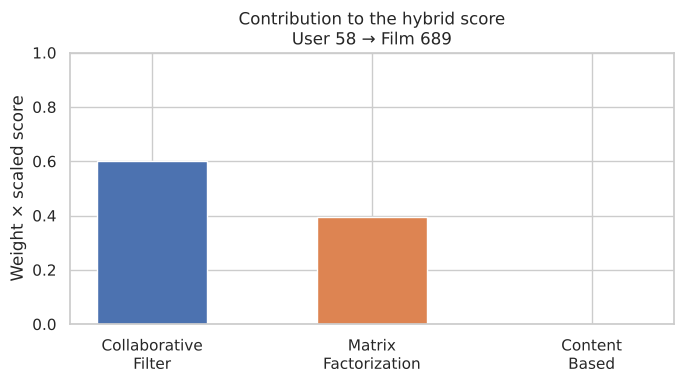

In [14]:
# How each model contributes to the top recommendation: its score scaled to
# 0-1 (as the hybrid uses it) times its weight. The contributions add up to the hybrid score.
sample_movie_id = recs_df.iloc[0]['movieId']
candidates, cf_scaled, mf_scaled, cb_scaled = hybrid.component_scores(sample_uid)
pos = int(np.flatnonzero(candidates == loader.item_id_map[sample_movie_id])[0])
weights = {'cf': hybrid.w_cf, 'mf': hybrid.w_mf, 'cb': hybrid.w_cb}
scaled = {'cf': cf_scaled[pos], 'mf': mf_scaled[pos], 'cb': cb_scaled[pos]}
contribution = {m: weights[m] * scaled[m] for m in weights}

explanation = hybrid.explain(sample_uid, sample_movie_id)
print(f"Score breakdown for User {sample_uid} → '{recs_df.iloc[0]['title']}'")
for m, label in [('cf', 'CF'), ('mf', 'MF'), ('cb', 'CB')]:
    print(f"  {label}: raw {explanation[m + '_score']}, scaled {scaled[m]:.3f}, "
          f"weight {weights[m]:.0%}, contribution {contribution[m]:.3f}")
print(f"  Hybrid score: {sum(contribution.values()):.3f}")

# Bar chart
fig, ax = plt.subplots(figsize=(7, 4))
models = ['Collaborative\nFilter', 'Matrix\nFactorization', 'Content\nBased']
colors = ['#4C72B0', '#DD8452', '#55A868']
ax.bar(models, [contribution['cf'], contribution['mf'], contribution['cb']],
       color=colors, edgecolor='white', width=0.5)
ax.set_title(f"Contribution to the hybrid score\nUser {sample_uid} → {recs_df.iloc[0]['title']}", fontsize=12)
ax.set_ylabel('Weight × scaled score')
ax.set_ylim(0, 1)
plt.tight_layout()
plt.savefig('../docs/explainability.png', dpi=150, bbox_inches='tight')
plt.show()